In [13]:
import os
import glob
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from sklearn.metrics import accuracy_score, f1_score, classification_report

SEED = 42

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed()
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.11.0


In [14]:
train_path = r"C:\Users\Tripti Mishra\Downloads\Mulberry Leaf Dataset\Mulberry Leaf Dataset\Training set"
test_path  = r"C:\Users\Tripti Mishra\Downloads\Mulberry Leaf Dataset\Mulberry Leaf Dataset\Test set"

In [21]:
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def list_images(folder):
    return [f for f in glob.glob(os.path.join(folder, "*"))
            if f.lower().endswith(IMG_EXTS)]

classes = sorted([
    folder for folder in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, folder))
])

data = []
for class_name in classes:
    train_count = len(list_images(os.path.join(train_path, class_name)))
    test_count  = len(list_images(os.path.join(test_path, class_name)))
    data.append([class_name, train_count, test_count])

df = pd.DataFrame(data, columns=["Class", "Training Images", "Testing Images"])
print(df.to_string(index=False))

                Class  Training Images  Testing Images
       01 ChiangMai60              400             100
           02 RedKing              264              86
         03 WhiteKing              388             153
    04 BlackOodTurkey              400             100
   05 TaiwanStraberry              391              97
    06 BlackAustralia              400             237
         07 Buriram60              276              69
  08 Kamphaengsaeng42              400             100
      09 TaiwanMeacho              400             240
10 ChiangMaiBuriram60              400             361


In [22]:
print("\nTotal training images:", df["Training Images"].sum())
print("Total testing images:", df["Testing Images"].sum())
print("Total images:", df["Training Images"].sum() + df["Testing Images"].sum())


Total training images: 3719
Total testing images: 1543
Total images: 5262


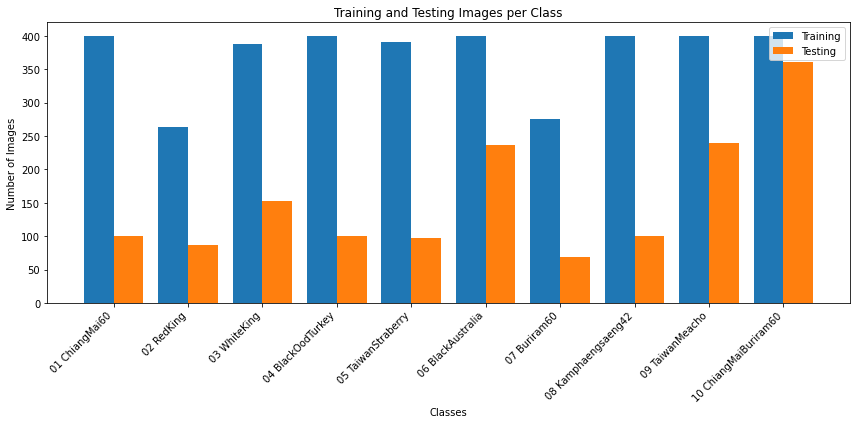

In [23]:
plt.figure(figsize=(12, 6))
x = np.arange(len(df))

plt.bar(x, df["Training Images"], width=0.4, label="Training")
plt.bar(x + 0.4, df["Testing Images"], width=0.4, label="Testing")

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Training and Testing Images per Class")
plt.xticks(x + 0.2, df["Class"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# EfficientNetB0 in Keras has built-in rescaling + normalization,
# so we feed raw 0–255 pixels (no rescale=1/255).
# Both generators use the same validation_split; Keras splits files
# deterministically, so train and validation never overlap.

train_datagen = ImageDataGenerator(
    validation_split=0.20,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True
)

validation_datagen = ImageDataGenerator(validation_split=0.20)

train_generator = train_datagen.flow_from_directory(
    train_path, target_size=(224, 224), batch_size=32,
    class_mode="categorical", subset="training",
    shuffle=True, seed=SEED
)

validation_generator = validation_datagen.flow_from_directory(
    train_path, target_size=(224, 224), batch_size=32,
    class_mode="categorical", subset="validation",
    shuffle=False, seed=SEED
)

print("Training images:", train_generator.samples)
print("Validation images:", validation_generator.samples)
print("Classes:", train_generator.class_indices)

Found 2977 images belonging to 10 classes.
Found 742 images belonging to 10 classes.
Training images: 2977
Validation images: 742
Classes: {'01 ChiangMai60': 0, '02 RedKing': 1, '03 WhiteKing': 2, '04 BlackOodTurkey': 3, '05 TaiwanStraberry': 4, '06 BlackAustralia': 5, '07 Buriram60': 6, '08 Kamphaengsaeng42': 7, '09 TaiwanMeacho': 8, '10 ChiangMaiBuriram60': 9}


In [25]:
class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)

train_counts = np.bincount(train_generator.classes, minlength=num_classes)
val_counts   = np.bincount(validation_generator.classes, minlength=num_classes)
test_counts  = [len(list_images(os.path.join(test_path, c))) for c in class_names]

df_split = pd.DataFrame({
    "Class": class_names,
    "Training": train_counts,
    "Validation": val_counts,
    "Testing": test_counts
})

print(df_split.to_string(index=False))
print("\nTotal Training Images:", df_split["Training"].sum())
print("Total Validation Images:", df_split["Validation"].sum())
print("Total Testing Images:", df_split["Testing"].sum())
print("Total Images:", df_split[["Training", "Validation", "Testing"]].sum().sum())

                Class  Training  Validation  Testing
       01 ChiangMai60       320          80      100
           02 RedKing       212          52       86
         03 WhiteKing       311          77      153
    04 BlackOodTurkey       320          80      100
   05 TaiwanStraberry       313          78       97
    06 BlackAustralia       320          80      237
         07 Buriram60       221          55       69
  08 Kamphaengsaeng42       320          80      100
      09 TaiwanMeacho       320          80      240
10 ChiangMaiBuriram60       320          80      361

Total Training Images: 2977
Total Validation Images: 742
Total Testing Images: 1543
Total Images: 5262


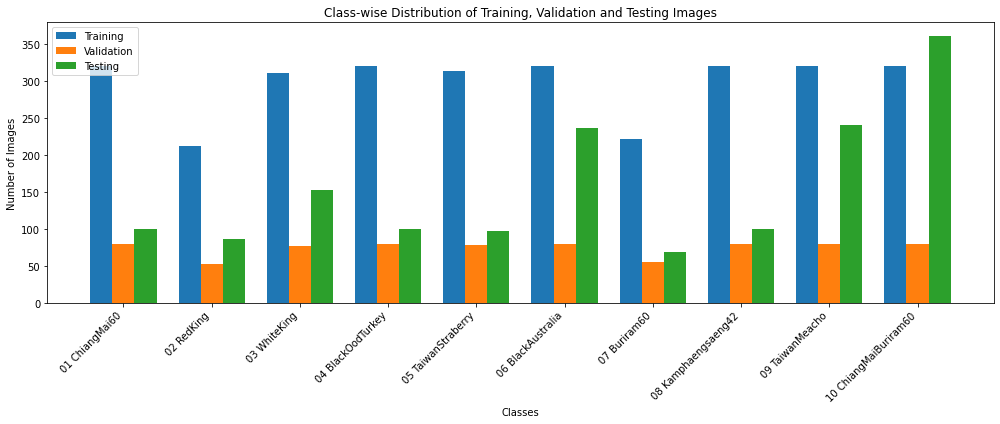

In [27]:
plt.figure(figsize=(14, 6))
x = np.arange(len(df_split))
width = 0.25

plt.bar(x - width, df_split["Training"], width, label="Training")
plt.bar(x, df_split["Validation"], width, label="Validation")
plt.bar(x + width, df_split["Testing"], width, label="Testing")

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Class-wise Distribution of Training, Validation and Testing Images")
plt.xticks(x, df_split["Class"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
train_images = []
for c in classes:
    train_images.extend(list_images(os.path.join(train_path, c)))

image = Image.open(train_images[0])
print("Image size:", image.size)
print("Image mode:", image.mode)

Image size: (224, 224)
Image mode: RGB


In [29]:
def build_eff_model(seed=SEED):
    set_seed(seed)
    base = EfficientNetB0(weights="imagenet", include_top=False,
                          input_shape=(224, 224, 3))
    base.trainable = False

    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.3)(x)
    out = Dense(num_classes, activation="softmax")(x)

    model = Model(inputs=base.input, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model_eff = build_eff_model()
print("Total params:", model_eff.count_params())
print("Trainable params:",
      int(sum(np.prod(w.shape) for w in model_eff.trainable_weights)))

Total params: 4214829
Trainable params: 165258


In [30]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

start_time = time.time()
history_eff = model_eff.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stop]
)
training_time_eff = time.time() - start_time

h = history_eff.history
best_epoch = int(np.argmin(h["val_loss"]))   # epoch whose weights were restored

print(f"\nEpochs run: {len(h['loss'])}")
print(f"Training time: {training_time_eff / 60:.2f} minutes")
print(f"Restored (best val_loss) epoch: {best_epoch + 1}")
print(f"Val accuracy of restored model: {h['val_accuracy'][best_epoch] * 100:.2f}%")
print(f"(Highest val accuracy seen in any epoch: {max(h['val_accuracy']) * 100:.2f}%)")

Epoch 1/20
94/94 [==============================] - 136s 1s/step - loss: 1.4352 - accuracy: 0.5099 - val_loss: 1.1298 - val_accuracy: 0.6159
Epoch 2/20
94/94 [==============================] - 132s 1s/step - loss: 0.8203 - accuracy: 0.7424 - val_loss: 0.9396 - val_accuracy: 0.6685
Epoch 3/20
94/94 [==============================] - 129s 1s/step - loss: 0.6675 - accuracy: 0.7773 - val_loss: 0.8075 - val_accuracy: 0.7372
Epoch 4/20
94/94 [==============================] - 123s 1s/step - loss: 0.5583 - accuracy: 0.8153 - val_loss: 0.8317 - val_accuracy: 0.7156
Epoch 5/20
94/94 [==============================] - 120s 1s/step - loss: 0.4960 - accuracy: 0.8475 - val_loss: 0.7140 - val_accuracy: 0.7709
Epoch 6/20
94/94 [==============================] - 120s 1s/step - loss: 0.4431 - accuracy: 0.8556 - val_loss: 0.7101 - val_accuracy: 0.7682
Epoch 7/20
94/94 [==============================] - 120s 1s/step - loss: 0.4116 - accuracy: 0.8656 - val_loss: 0.6550 - val_accuracy: 0.7776
Epoch 8/20
94

In [31]:
validation_generator.reset()
val_probs = model_eff.predict(validation_generator, verbose=1)
val_pred  = val_probs.argmax(axis=1)
val_true  = validation_generator.classes

val_acc = accuracy_score(val_true, val_pred)
val_f1  = f1_score(val_true, val_pred, average="macro")

print(f"Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Validation Macro-F1: {val_f1:.4f}\n")
print(classification_report(val_true, val_pred, target_names=class_names, digits=4))

model_eff.save_weights("mulberry_efficientnetb0_weights.h5")
print("Model weights saved (these are the restored best-epoch weights).")

24/24 [==============================] - 25s 969ms/step
Validation Accuracy: 77.76%
Validation Macro-F1: 0.7775

                       precision    recall  f1-score   support

       01 ChiangMai60     0.8434    0.8750    0.8589        80
           02 RedKing     0.8511    0.7692    0.8081        52
         03 WhiteKing     0.8696    0.7792    0.8219        77
    04 BlackOodTurkey     0.7528    0.8375    0.7929        80
   05 TaiwanStraberry     0.7436    0.7436    0.7436        78
    06 BlackAustralia     0.8095    0.6375    0.7133        80
         07 Buriram60     0.7800    0.7091    0.7429        55
  08 Kamphaengsaeng42     0.8987    0.8875    0.8931        80
      09 TaiwanMeacho     0.6667    0.6500    0.6582        80
10 ChiangMaiBuriram60     0.6509    0.8625    0.7419        80

             accuracy                         0.7776       742
            macro avg     0.7866    0.7751    0.7775       742
         weighted avg     0.7842    0.7776    0.7774       742

Mo

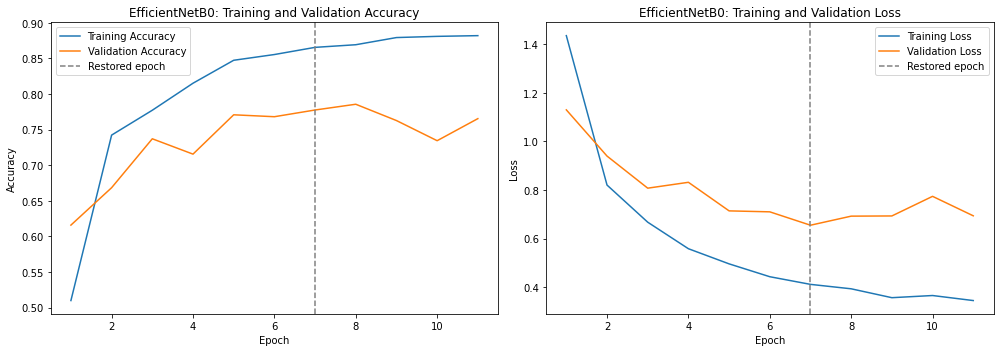

In [32]:
epochs_range = range(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, h["accuracy"], label="Training Accuracy")
axes[0].plot(epochs_range, h["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("EfficientNetB0: Training and Validation Accuracy")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")

axes[1].plot(epochs_range, h["loss"], label="Training Loss")
axes[1].plot(epochs_range, h["val_loss"], label="Validation Loss")
axes[1].set_title("EfficientNetB0: Training and Validation Loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")

for ax in axes:
    ax.axvline(best_epoch + 1, color="gray", linestyle="--", label="Restored epoch")
    ax.legend()

plt.tight_layout()
plt.show()

In [33]:
# Same 80/20 split as before, but no augmentation and shuffle=False,
# so every image keeps a fixed index. Needed for the curriculum ordering.
plain_datagen = ImageDataGenerator(validation_split=0.20)
plain_kw = dict(target_size=(224, 224), batch_size=32,
                class_mode="sparse", shuffle=False)

tr_plain = plain_datagen.flow_from_directory(train_path, subset="training", **plain_kw)
va_plain = plain_datagen.flow_from_directory(train_path, subset="validation", **plain_kw)
te_plain = ImageDataGenerator().flow_from_directory(test_path, **plain_kw)

# Sanity checks: same split and same class mapping as the baseline
assert tr_plain.filenames == train_generator.filenames
assert va_plain.filenames == validation_generator.filenames
assert te_plain.class_indices == train_generator.class_indices
print("Split and class mapping match the baseline.")

Found 2977 images belonging to 10 classes.
Found 742 images belonging to 10 classes.
Found 1543 images belonging to 10 classes.
Split and class mapping match the baseline.


In [34]:
extractor = EfficientNetB0(weights="imagenet", include_top=False,
                           pooling="avg", input_shape=(224, 224, 3))

t0 = time.time()
X_tr = extractor.predict(tr_plain, verbose=1); y_tr = tr_plain.classes
X_va = extractor.predict(va_plain, verbose=1); y_va = va_plain.classes
X_te = extractor.predict(te_plain, verbose=1); y_te = te_plain.classes
print(f"Feature extraction time: {(time.time() - t0) / 60:.2f} minutes")

np.savez("b0_features.npz",
         X_tr=X_tr, y_tr=y_tr, X_va=X_va, y_va=y_va, X_te=X_te, y_te=y_te,
         tr_files=np.array(tr_plain.filepaths))

print("Train:", X_tr.shape, " Val:", X_va.shape, " Test:", X_te.shape)

49/49 [==============================] - 50s 1s/step
Feature extraction time: 3.03 minutes
Train: (2977, 1280)  Val: (742, 1280)  Test: (1543, 1280)


In [35]:
data = np.load("b0_features.npz")
X_tr, y_tr = data["X_tr"], data["y_tr"]
X_va, y_va = data["X_va"], data["y_va"]
X_te, y_te = data["X_te"], data["y_te"]
tr_files = data["tr_files"]
print("Loaded:", X_tr.shape, X_va.shape, X_te.shape)

Loaded: (2977, 1280) (742, 1280) (1543, 1280)


In [36]:
def l2_normalize(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

Z_tr = l2_normalize(X_tr)

# Class prototypes (centres), computed from training data only
centroids = l2_normalize(np.stack([Z_tr[y_tr == c].mean(axis=0)
                                   for c in range(num_classes)]))

sims = Z_tr @ centroids.T                          # cosine similarity to every centre
idx = np.arange(len(y_tr))
own_sim = sims[idx, y_tr]

other = sims.copy()
other[idx, y_tr] = -np.inf
closest_other_sim = other.max(axis=1)
closest_other_cls = other.argmax(axis=1)

margin = own_sim - closest_other_sim               # higher = easier
difficulty = -margin                               # higher = harder
order_easy = np.argsort(difficulty)                # easiest first

print(f"Difficulty range: {difficulty.min():.4f} to {difficulty.max():.4f}")
print(f"Samples closer to another class's centre (margin < 0): "
      f"{(margin < 0).sum()} / {len(margin)} ({(margin < 0).mean() * 100:.1f}%)")

Difficulty range: -0.2131 to 0.1175
Samples closer to another class's centre (margin < 0): 865 / 2977 (29.1%)


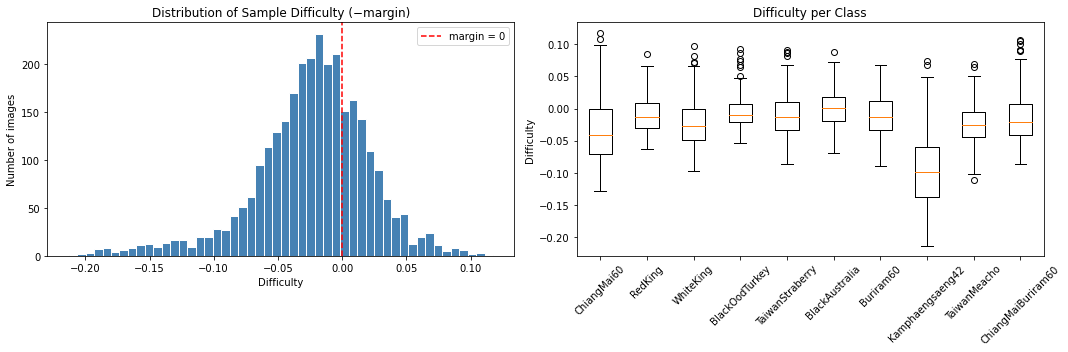

                Class  Mean difficulty  % margin < 0
    06 BlackAustralia           0.0005       51.8750
    04 BlackOodTurkey          -0.0056       33.7500
           02 RedKing          -0.0096       32.5472
         07 Buriram60          -0.0116       37.1041
   05 TaiwanStraberry          -0.0120       34.5048
10 ChiangMaiBuriram60          -0.0139       29.3750
         03 WhiteKing          -0.0229       24.4373
      09 TaiwanMeacho          -0.0235       19.6875
       01 ChiangMai60          -0.0333       25.0000
  08 Kamphaengsaeng42          -0.0957        5.9375


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(difficulty, bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(0, color="red", linestyle="--", label="margin = 0")
axes[0].set_title("Distribution of Sample Difficulty (−margin)")
axes[0].set_xlabel("Difficulty"); axes[0].set_ylabel("Number of images")
axes[0].legend()

axes[1].boxplot([difficulty[y_tr == c] for c in range(num_classes)],
                labels=[n.split(" ", 1)[1] for n in class_names])
axes[1].set_title("Difficulty per Class")
axes[1].set_ylabel("Difficulty")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

diff_table = pd.DataFrame({
    "Class": class_names,
    "Mean difficulty": [difficulty[y_tr == c].mean() for c in range(num_classes)],
    "% margin < 0": [(margin[y_tr == c] < 0).mean() * 100 for c in range(num_classes)],
}).sort_values("Mean difficulty", ascending=False)
print(diff_table.round(4).to_string(index=False))

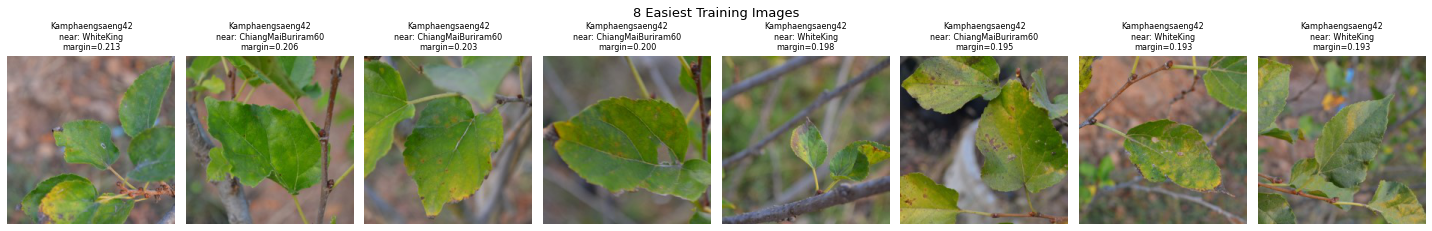

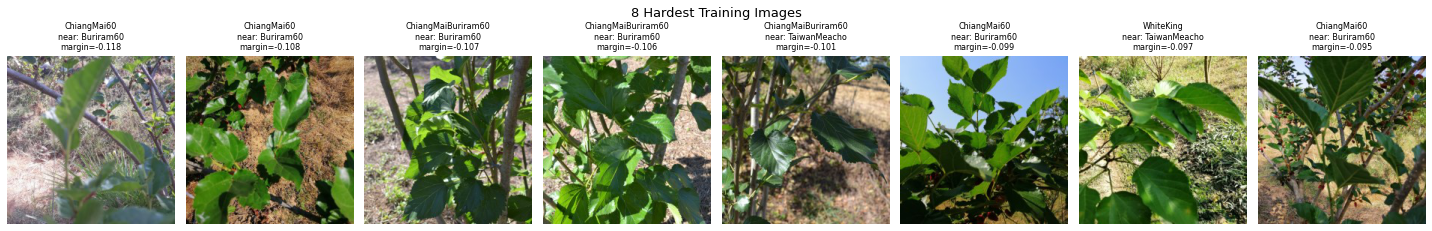

In [38]:
short = [n.split(" ", 1)[1] for n in class_names]

def show_grid(indices, title):
    fig, axes = plt.subplots(1, 8, figsize=(20, 3.5))
    for ax, i in zip(axes, indices):
        ax.imshow(Image.open(tr_files[i]))
        ax.set_title(f"{short[y_tr[i]]}\nnear: {short[closest_other_cls[i]]}\n"
                     f"margin={margin[i]:.3f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

show_grid(order_easy[:8], "8 Easiest Training Images")
show_grid(order_easy[-8:][::-1], "8 Hardest Training Images")

In [39]:
Z_va = l2_normalize(X_va)
sims_va = Z_va @ centroids.T
iv = np.arange(len(y_va))
own_va = sims_va[iv, y_va]
oth_va = sims_va.copy(); oth_va[iv, y_va] = -np.inf
difficulty_va = -(own_va - oth_va.max(axis=1))

quartile = pd.qcut(difficulty_va, 4, labels=["Q1 (easiest)", "Q2", "Q3", "Q4 (hardest)"])
check = pd.DataFrame({"quartile": quartile, "correct": (val_pred == y_va)})
print("Baseline validation accuracy by difficulty quartile:")
print((check.groupby("quartile")["correct"].mean() * 100).round(2))

Baseline validation accuracy by difficulty quartile:
quartile
Q1 (easiest)    98.92
Q2              87.57
Q3              80.00
Q4 (hardest)    44.62
Name: correct, dtype: float64


In [40]:
# Percentile of each sample's difficulty within its own class (0 = easiest, 1 = hardest)
within_pct = np.zeros(len(y_tr))
for c in range(num_classes):
    m = np.where(y_tr == c)[0]
    ranks = difficulty[m].argsort().argsort()
    within_pct[m] = (ranks + 0.5) / len(m)

# Primary key: within-class percentile; tie-break: raw difficulty
order_easy_bal = np.lexsort((difficulty, within_pct))
print("Balanced ordering created:", order_easy_bal.shape)

Balanced ordering created: (2977,)


Class composition of the easiest 30% (893 images):
             Class  Global sort  Class-balanced  Full train set
       ChiangMai60          166              96             320
           RedKing           23              64             212
         WhiteKing          111              93             311
    BlackOodTurkey            7              96             320
   TaiwanStraberry           66              94             313
    BlackAustralia           27              96             320
         Buriram60           46              66             221
  Kamphaengsaeng42          269              96             320
      TaiwanMeacho           96              96             320
ChiangMaiBuriram60           82              96             320


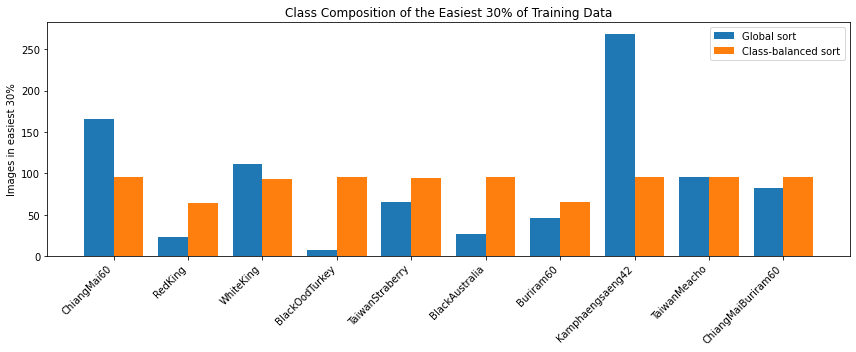

In [41]:
n30 = int(0.30 * len(y_tr))
comp = pd.DataFrame({
    "Class": short,
    "Global sort": np.bincount(y_tr[order_easy[:n30]], minlength=num_classes),
    "Class-balanced": np.bincount(y_tr[order_easy_bal[:n30]], minlength=num_classes),
    "Full train set": np.bincount(y_tr, minlength=num_classes),
})
print(f"Class composition of the easiest 30% ({n30} images):")
print(comp.to_string(index=False))

x = np.arange(num_classes)
plt.figure(figsize=(12, 5))
plt.bar(x - 0.2, comp["Global sort"], 0.4, label="Global sort")
plt.bar(x + 0.2, comp["Class-balanced"], 0.4, label="Class-balanced sort")
plt.xticks(x, short, rotation=45, ha="right")
plt.ylabel("Images in easiest 30%")
plt.title("Class Composition of the Easiest 30% of Training Data")
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
EPOCHS = 30
BATCH = 32
SEEDS = [0, 1, 2]
PACE_START, PACE_RAMP = 0.30, 10     # start with 30% of data, reach 100% at epoch 11

def build_head(seed):
    """Same classifier head as the baseline: Dense(128) -> Dropout(0.3) -> Dense(10)."""
    set_seed(seed)
    m = tf.keras.Sequential([
        tf.keras.Input(shape=(X_tr.shape[1],)),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(num_classes, activation="softmax"),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
    return m

def pacing(epoch):
    """Fraction of (easiest) training data used at a 0-indexed epoch."""
    return min(1.0, PACE_START + (1 - PACE_START) * epoch / PACE_RAMP)

print("Fraction of data used per epoch (curriculum):")
print([round(pacing(e), 2) for e in range(EPOCHS)])

Fraction of data used per epoch (curriculum):
[0.3, 0.37, 0.44, 0.51, 0.58, 0.65, 0.72, 0.79, 0.86, 0.93, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [54]:
q_va = pd.qcut(difficulty_va, 4, labels=False)   # 0 = easiest quartile, 3 = hardest (from Cell 20)
def run_experiment(mode, seed):
    model = build_head(seed)
    rng = np.random.default_rng(seed)
    rows, cum_time, samples_seen = [], 0.0, 0

    for ep in range(EPOCHS):
        if mode == "Random":
            idx = rng.permutation(len(y_tr))                        # all data, random order
        else:
            n = int(round(pacing(ep) * len(y_tr)))
            if mode == "Curriculum":
                idx = order_easy_bal[:n]                            # easiest n, strict easy -> hard
            else:  # "Curriculum-Shuffled"
                idx = rng.permutation(order_easy_bal[:n])           # easiest n, shuffled

        t0 = time.time()
        h = model.fit(X_tr[idx], y_tr[idx], batch_size=BATCH, epochs=1,
                      shuffle=False, verbose=0)
        cum_time += time.time() - t0                           # only training is timed
        samples_seen += len(idx)

        pred = model.predict(X_va, verbose=0).argmax(axis=1)
        rows.append(dict(method=mode, seed=seed, epoch=ep + 1,
                         n_used=len(idx), samples_seen=samples_seen,
                         train_loss=h.history["loss"][0],
                         train_acc=h.history["accuracy"][0],
                         val_acc=accuracy_score(y_va, pred),
                         val_f1=f1_score(y_va, pred, average="macro"),
                         cum_time=cum_time,
                         **{f"val_acc_Q{q+1}": (pred[q_va == q] == y_va[q_va == q]).mean()
                            for q in range(4)}))
    return model, pd.DataFrame(rows)

In [64]:
trained_models, histories = {}, []

for mode in ["Random", "Curriculum", "Curriculum-Shuffled"]:
    for seed in SEEDS:
        model, hist = run_experiment(mode, seed)
        trained_models[(mode, seed)] = model
        histories.append(hist)
        best = hist.loc[hist.val_acc.idxmax()]
        print(f"{mode:20s} seed={seed}  best val_acc={best.val_acc:.4f} (epoch {int(best.epoch)})  "
              f"final val_acc={hist.val_acc.iloc[-1]:.4f}  time={hist.cum_time.iloc[-1]:.1f}s")

all_hist = pd.concat(histories, ignore_index=True)
all_hist.to_csv("curriculum_vs_random_history.csv", index=False)

Random               seed=0  best val_acc=0.8154 (epoch 16)  final val_acc=0.8154  time=11.8s
Random               seed=1  best val_acc=0.8248 (epoch 26)  final val_acc=0.8046  time=16.9s
Random               seed=2  best val_acc=0.8248 (epoch 23)  final val_acc=0.8100  time=11.5s
Curriculum           seed=0  best val_acc=0.8059 (epoch 29)  final val_acc=0.7925  time=10.9s
Curriculum           seed=1  best val_acc=0.8005 (epoch 28)  final val_acc=0.7857  time=13.4s
Curriculum           seed=2  best val_acc=0.8005 (epoch 27)  final val_acc=0.7857  time=10.4s
Curriculum-Shuffled  seed=0  best val_acc=0.8154 (epoch 29)  final val_acc=0.7898  time=10.1s
Curriculum-Shuffled  seed=1  best val_acc=0.8167 (epoch 22)  final val_acc=0.8005  time=9.2s
Curriculum-Shuffled  seed=2  best val_acc=0.8221 (epoch 29)  final val_acc=0.7992  time=10.3s


In [56]:
random_best_mean = all_hist[all_hist.method == "Random"].groupby("seed").val_acc.max().mean()
TARGET = round(0.95 * random_best_mean, 4)
print(f"Target validation accuracy = 95% of Random's mean best = {TARGET:.4f}\n")

def first_hit(df, target):
    hit = df[df.val_acc >= target]
    return (int(hit.epoch.iloc[0]), hit.cum_time.iloc[0]) if len(hit) else (np.nan, np.nan)

rows = []
for (mode, seed), df in all_hist.groupby(["method", "seed"]):
    ep_t, time_t = first_hit(df, TARGET)
    rows.append(dict(Method=mode, Seed=seed,
                     Best_Val_Acc=df.val_acc.max(),
                     Final_Val_Acc=df.val_acc.iloc[-1],
                     Best_Macro_F1=df.val_f1.max(),
                     Final_Macro_F1=df.val_f1.iloc[-1],
                     Epochs_to_Target=ep_t,
                     Time_to_Target_s=time_t,
                     Total_Train_Time_s=df.cum_time.iloc[-1]))

per_seed = pd.DataFrame(rows)
print("Per-seed results:")
print(per_seed.round(4).to_string(index=False))

summary = per_seed.drop(columns="Seed").groupby("Method").agg(["mean", "std"]).round(4)
print("\nMean ± std over 3 seeds:")
print(summary.T.to_string())

Target validation accuracy = 95% of Random's mean best = 0.7806

Per-seed results:
             Method  Seed  Best_Val_Acc  Final_Val_Acc  Best_Macro_F1  Final_Macro_F1  Epochs_to_Target  Time_to_Target_s  Total_Train_Time_s
         Curriculum     0        0.8059         0.7925         0.8102          0.7962                29            8.7871              9.1095
         Curriculum     1        0.8005         0.7857         0.8035          0.7875                16            4.6864              8.9771
         Curriculum     2        0.8005         0.7857         0.8052          0.7900                18            5.0660              8.7371
Curriculum-Shuffled     0        0.8154         0.7898         0.8179          0.7928                11            2.9857              8.9296
Curriculum-Shuffled     1        0.8167         0.8005         0.8195          0.8034                12            3.2777              8.7109
Curriculum-Shuffled     2        0.8221         0.7992         0.

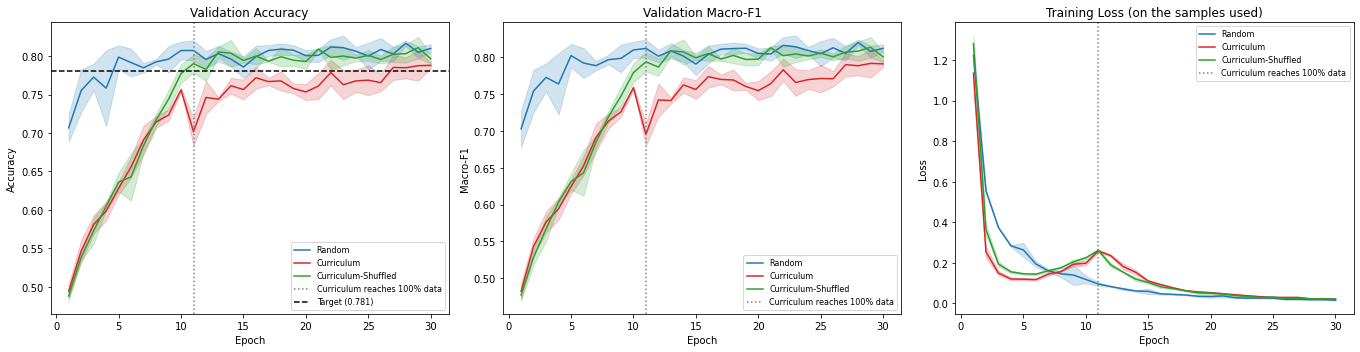

In [58]:
methods = ["Random", "Curriculum", "Curriculum-Shuffled"]
colors = {"Random": "tab:blue", "Curriculum": "tab:red", "Curriculum-Shuffled": "tab:green"}

num_cols = all_hist.select_dtypes(include="number").columns.drop("epoch")
g = all_hist.groupby(["method", "epoch"])[num_cols]
mean_h = g.mean().reset_index()
std_h = g.std().reset_index()

def plot_metric(ax, col, title, ylabel):
    for m in methods:
        mu, sd = mean_h[mean_h.method == m], std_h[std_h.method == m]
        ax.plot(mu.epoch, mu[col], label=m, color=colors[m])
        ax.fill_between(mu.epoch, mu[col] - sd[col], mu[col] + sd[col],
                        alpha=0.2, color=colors[m])
    ax.axvline(PACE_RAMP + 1, ls=":", color="gray", label="Curriculum reaches 100% data")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_metric(axes[0], "val_acc", "Validation Accuracy", "Accuracy")
axes[0].axhline(TARGET, ls="--", color="black", label=f"Target ({TARGET:.3f})")
plot_metric(axes[1], "val_f1", "Validation Macro-F1", "Macro-F1")
plot_metric(axes[2], "train_loss", "Training Loss (on the samples used)", "Loss")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

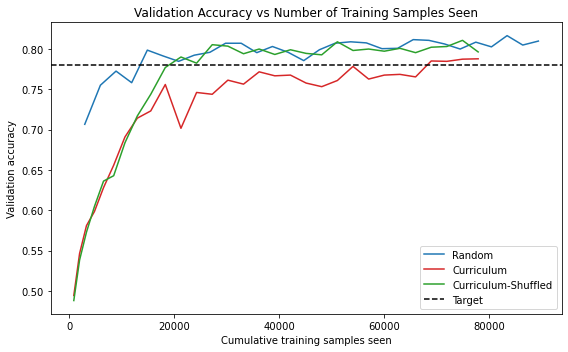

In [59]:
fig, ax = plt.subplots(figsize=(8, 5))
for m in methods:
    mu = mean_h[mean_h.method == m]
    ax.plot(mu.samples_seen, mu.val_acc, label=m, color=colors[m])
ax.axhline(TARGET, ls="--", color="black", label="Target")
ax.set_title("Validation Accuracy vs Number of Training Samples Seen")
ax.set_xlabel("Cumulative training samples seen"); ax.set_ylabel("Validation accuracy")
ax.legend(); plt.tight_layout(); plt.show()

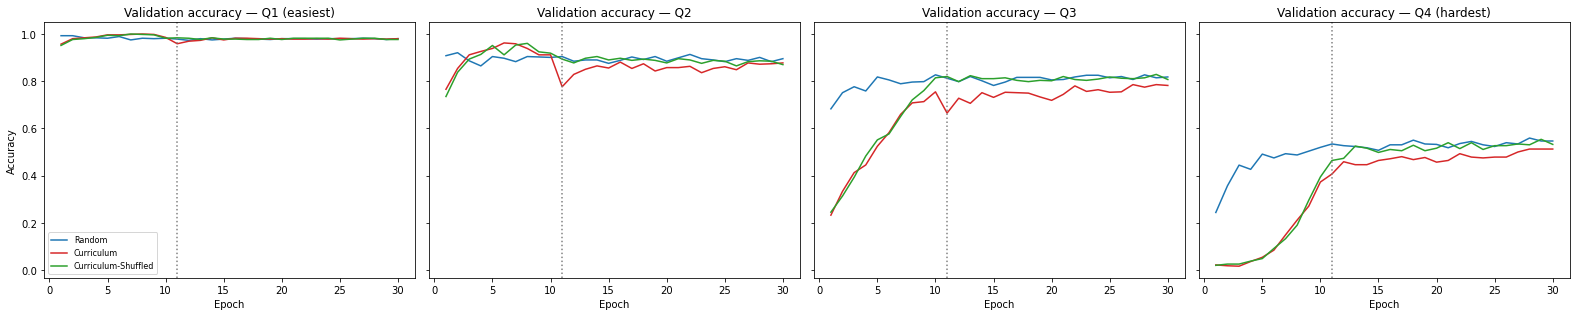

Mean per-quartile validation accuracy at selected epochs:
             method  epoch  val_acc_Q1  val_acc_Q2  val_acc_Q3  val_acc_Q4
         Curriculum      1       0.957       0.766       0.232       0.022
         Curriculum      3       0.984       0.912       0.413       0.016
         Curriculum      6       0.996       0.962       0.582       0.084
         Curriculum     11       0.959       0.777       0.665       0.407
         Curriculum     30       0.980       0.877       0.782       0.513
Curriculum-Shuffled      1       0.952       0.735       0.245       0.020
Curriculum-Shuffled      3       0.980       0.894       0.393       0.025
Curriculum-Shuffled      6       0.993       0.912       0.577       0.091
Curriculum-Shuffled     11       0.984       0.894       0.820       0.464
Curriculum-Shuffled     30       0.977       0.870       0.807       0.532
             Random      1       0.993       0.908       0.683       0.244
             Random      3       0.984    

In [60]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5), sharey=True)
qnames = ["Q1 (easiest)", "Q2", "Q3", "Q4 (hardest)"]
for q, ax in enumerate(axes):
    col = f"val_acc_Q{q+1}"
    for m in methods:
        mu = mean_h[mean_h.method == m]
        ax.plot(mu.epoch, mu[col], label=m, color=colors[m])
    ax.axvline(PACE_RAMP + 1, ls=":", color="gray")
    ax.set_title(f"Validation accuracy — {qnames[q]}"); ax.set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Mean per-quartile validation accuracy at selected epochs:")
cols = [f"val_acc_Q{q+1}" for q in range(4)]
print(mean_h[mean_h.epoch.isin([1, 3, 6, 11, 30])][["method", "epoch"] + cols]
      .round(3).to_string(index=False))

In [61]:
test_rows = []
for (mode, seed), model in trained_models.items():
    pred = model.predict(X_te, verbose=0).argmax(axis=1)
    test_rows.append(dict(Method=mode, Seed=seed,
                          Test_Acc=accuracy_score(y_te, pred),
                          Test_Macro_F1=f1_score(y_te, pred, average="macro")))
test_df = pd.DataFrame(test_rows)

print("Test results per seed:")
print(test_df.round(4).to_string(index=False))

test_summary = test_df.drop(columns="Seed").groupby("Method").agg(["mean", "std"]).round(4)
print("\nTest results, mean ± std over 3 seeds:")
print(test_summary.to_string())

# Reference: the image-level EfficientNetB0 baseline (with augmentation) from Cell 11
te_plain.reset()
base_pred = model_eff.predict(te_plain, verbose=0).argmax(axis=1)
print(f"\nReference (image-level baseline, Cell 11): "
      f"Test Acc = {accuracy_score(y_te, base_pred):.4f}, "
      f"Test Macro-F1 = {f1_score(y_te, base_pred, average='macro'):.4f}")

Test results per seed:
             Method  Seed  Test_Acc  Test_Macro_F1
             Random     0    0.8159         0.8196
             Random     1    0.7907         0.7853
             Random     2    0.8121         0.8116
         Curriculum     0    0.7764         0.7896
         Curriculum     1    0.7686         0.7784
         Curriculum     2    0.7706         0.7822
Curriculum-Shuffled     0    0.7971         0.8043
Curriculum-Shuffled     1    0.7959         0.7944
Curriculum-Shuffled     2    0.8108         0.8117

Test results, mean ± std over 3 seeds:
                    Test_Acc         Test_Macro_F1        
                        mean     std          mean     std
Method                                                    
Curriculum            0.7719  0.0040        0.7834  0.0057
Curriculum-Shuffled   0.8013  0.0083        0.8035  0.0087
Random                0.8062  0.0136        0.8055  0.0179

Reference (image-level baseline, Cell 11): Test Acc = 0.7764, Test Macro

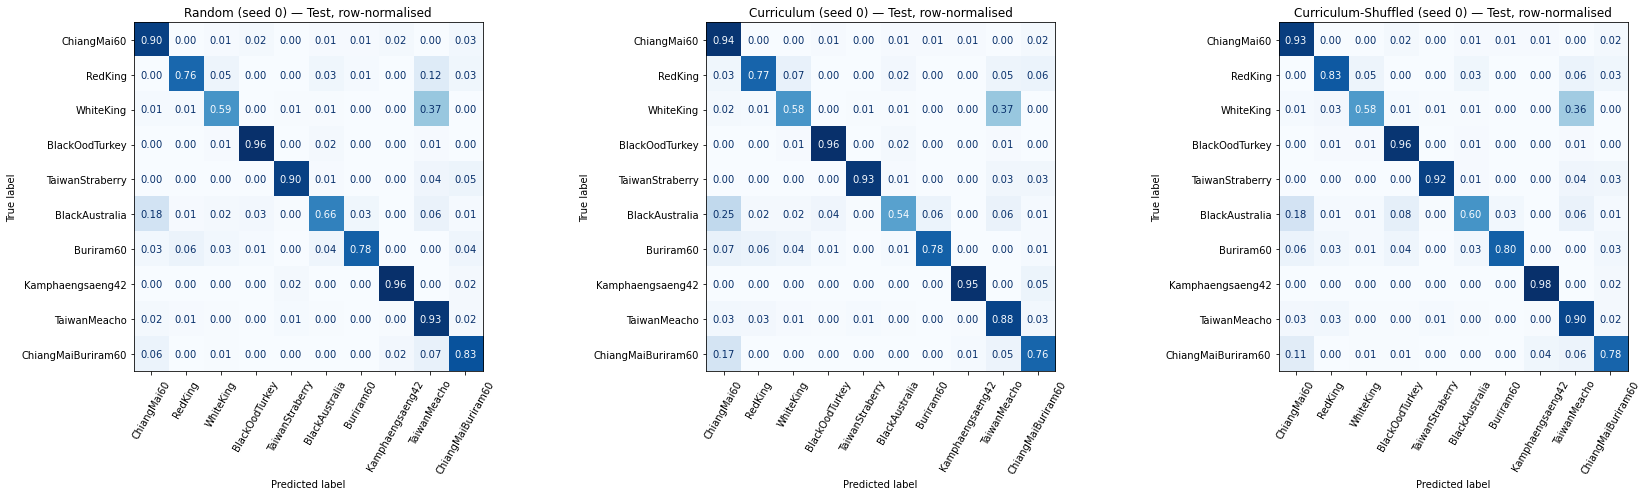

In [62]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, m in zip(axes, methods):
    pred = trained_models[(m, 0)].predict(X_te, verbose=0).argmax(axis=1)
    ConfusionMatrixDisplay.from_predictions(
        y_te, pred, display_labels=short, normalize="true",
        values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{m} (seed 0) — Test, row-normalised")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

In [63]:
per_class = {}
for m in methods:
    f1s = [f1_score(y_te, trained_models[(m, s)].predict(X_te, verbose=0).argmax(axis=1),
                    average=None) for s in SEEDS]
    per_class[m] = np.mean(f1s, axis=0)

per_class_df = pd.DataFrame(per_class, index=short).round(4)
per_class_df["Test support"] = np.bincount(y_te, minlength=num_classes)
print("Per-class test F1 (mean over 3 seeds):")
print(per_class_df.to_string())

Per-class test F1 (mean over 3 seeds):
                    Random  Curriculum  Curriculum-Shuffled  Test support
ChiangMai60         0.6889      0.5620               0.6802           100
RedKing             0.7993      0.7722               0.7892            86
WhiteKing           0.6999      0.6907               0.6884           153
BlackOodTurkey      0.9101      0.9194               0.9040           100
TaiwanStraberry     0.9203      0.9239               0.9192            97
BlackAustralia      0.7101      0.6699               0.7215           237
Buriram60           0.7487      0.7904               0.7734            69
Kamphaengsaeng42    0.9164      0.9058               0.9178           100
TaiwanMeacho        0.7776      0.7681               0.7716           240
ChiangMaiBuriram60  0.8836      0.8317               0.8692           361
